In [65]:
# import python libraries

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [66]:
# import csv file
df = pd.read_csv('Sales Data.csv', encoding= 'unicode_escape')

In [67]:
#(rows, columns)
df.shape

(11251, 15)

In [68]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  object 
 2   Product_ID        11251 non-null  object 
 3   Gender            11251 non-null  object 
 4   Age Group         11251 non-null  object 
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  object 
 8   Zone              11251 non-null  object 
 9   Occupation        11251 non-null  object 
 10  Product_Category  11251 non-null  object 
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), object(8)
memory usage: 1.3+ MB


In [70]:
#drop unrelated/blank columns
df.drop(['Status', 'unnamed1'], axis=1, inplace=True)

In [71]:
#check for null values
pd.isnull(df).sum()

User_ID              0
Cust_name            0
Product_ID           0
Gender               0
Age Group            0
Age                  0
Marital_Status       0
State                0
Zone                 0
Occupation           0
Product_Category     0
Orders               0
Amount              12
dtype: int64

In [72]:
# drop null values
df.dropna(inplace=True)


In [73]:
df['Amount'].dtypes

dtype('float64')

In [74]:
# change data type
df['Amount'] = df['Amount'].astype('int')

In [75]:
df['Amount'].dtypes

dtype('int64')

In [76]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [77]:
#rename column
df.rename(columns= {'Marital_Status':'Marriage'})

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marriage,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,M,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370
11247,1004089,Reichenbach,P00171342,M,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367
11248,1001209,Oshin,P00201342,F,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213
11249,1004023,Noonan,P00059442,M,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206


In [78]:
# describe() method returns description of the data in the DataFrame 
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.123900e+04,11239.000000,11239.000000,11239.000000,11239.000000
mean,1.003004e+06,35.410357,0.420055,2.489634,9453.610553
std,1.716039e+03,12.753866,0.493589,1.114967,5222.355168
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,2.000000,5443.000000
50%,1.003064e+06,33.000000,0.000000,2.000000,8109.000000
75%,1.004426e+06,43.000000,1.000000,3.000000,12675.000000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


In [79]:
# use describe() for specific columns
df[['Age', 'Orders', 'Amount']].describe()

,Age,Orders,Amount
count,11239.000000,11239.000000,11239.000000
mean,35.410357,2.489634,9453.610553
std,12.753866,1.114967,5222.355168
min,12.000000,1.000000,188.000000
25%,27.000000,2.000000,5443.000000
50%,33.000000,2.000000,8109.000000
75%,43.000000,3.000000,12675.000000
max,92.000000,4.000000,23952.000000


# Exploratory Data Analysis EDA

### Gender

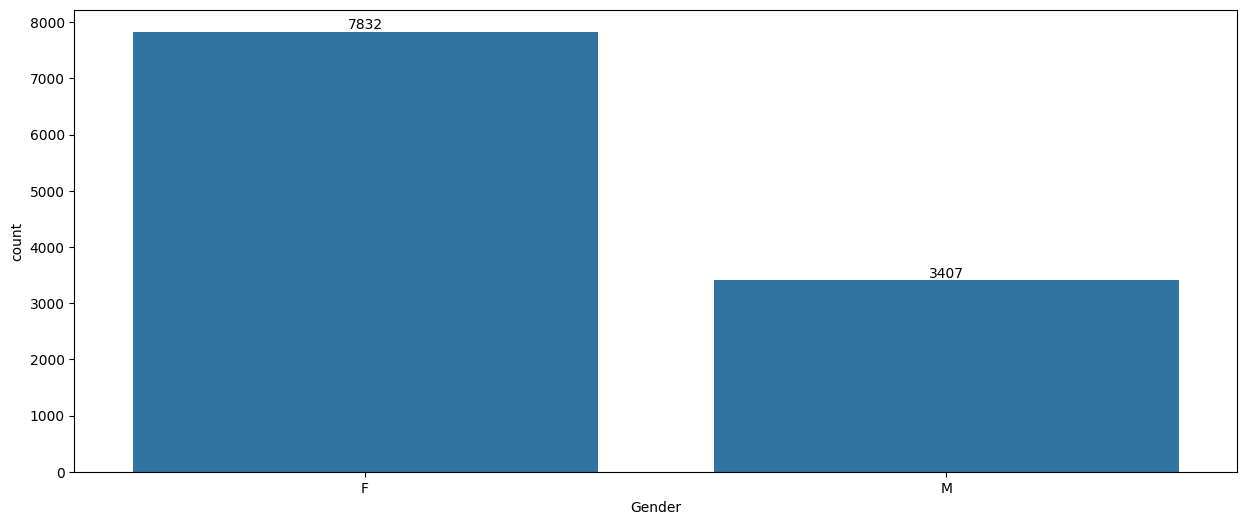

In [80]:
# plotting a bar chart for Gender and it's count

plt.figure(figsize=(15, 6))

ax = sns.countplot(x = 'Gender',data = df)

for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Gender', ylabel='Amount'>

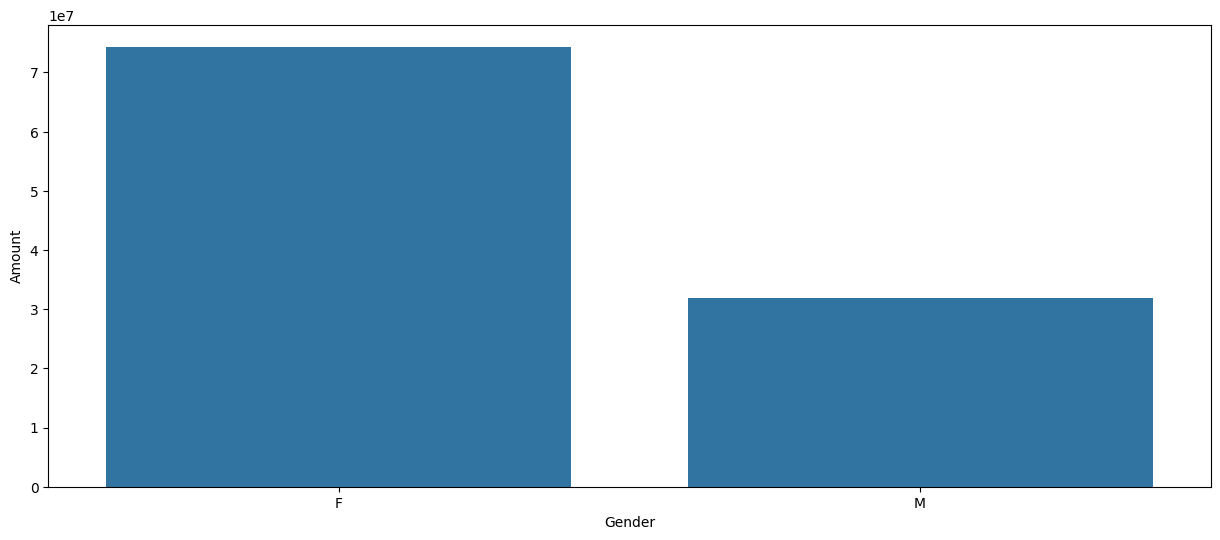

In [81]:
# plotting a bar chart for gender vs total amount

sales_gen = df.groupby(['Gender'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)

plt.figure(figsize=(15, 6))

sns.barplot(x = 'Gender',y= 'Amount' ,data = sales_gen)

### Age

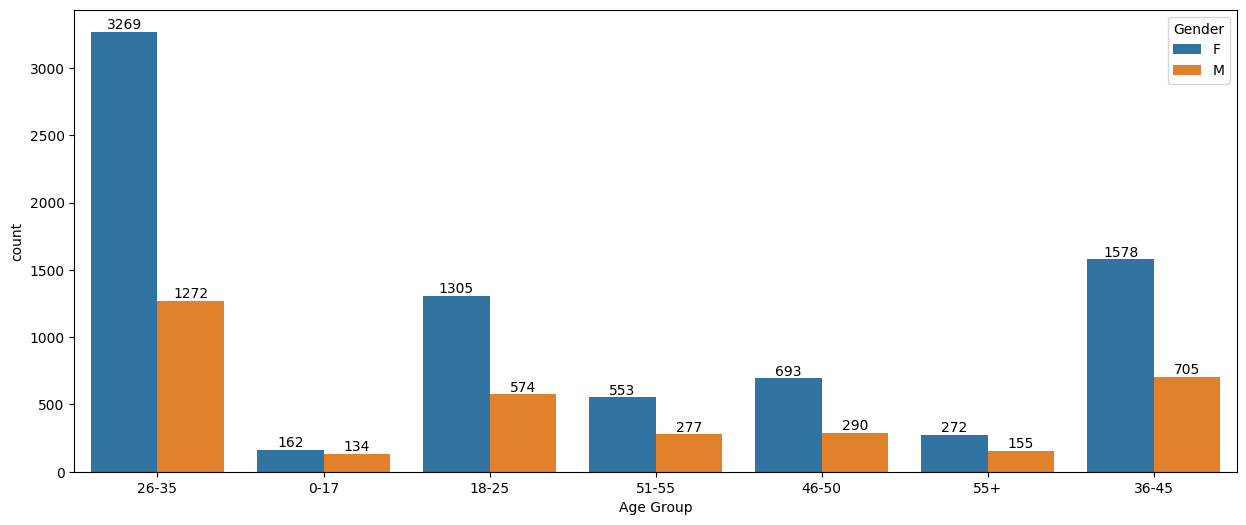

In [82]:
# plotting a bar chart for age group and it's gender count

plt.figure(figsize=(15, 6))

ax = sns.countplot(data = df, x = 'Age Group', hue = 'Gender')

for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Age Group', ylabel='Amount'>

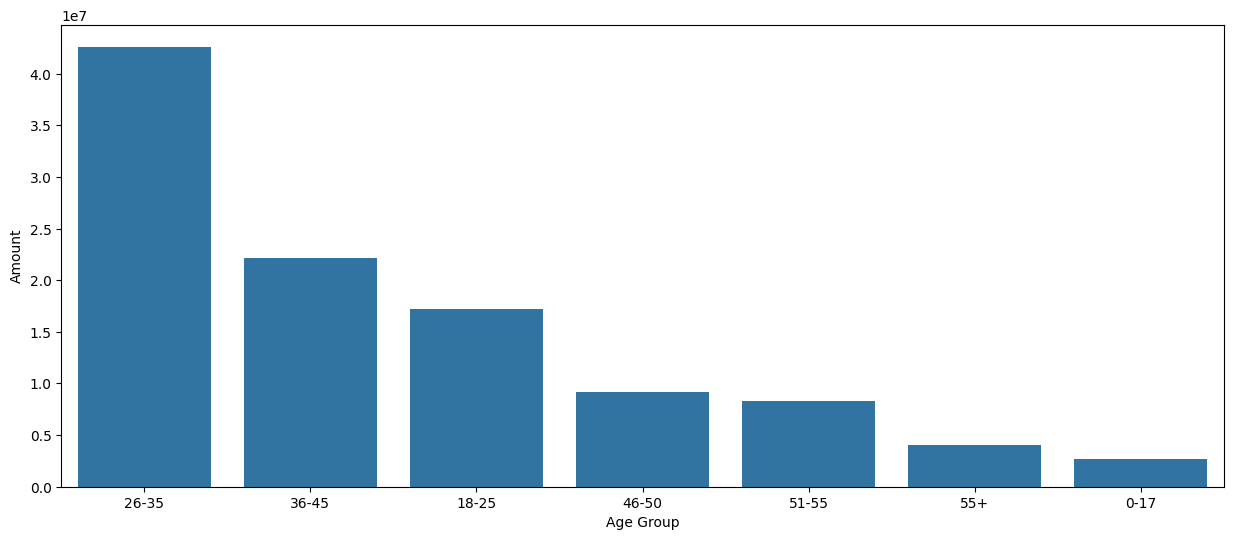

In [83]:
# Total Amount vs Age Group
sales_age = df.groupby(['Age Group'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)

plt.figure(figsize=(15, 6))

sns.barplot(x = 'Age Group',y= 'Amount' ,data = sales_age)

### State

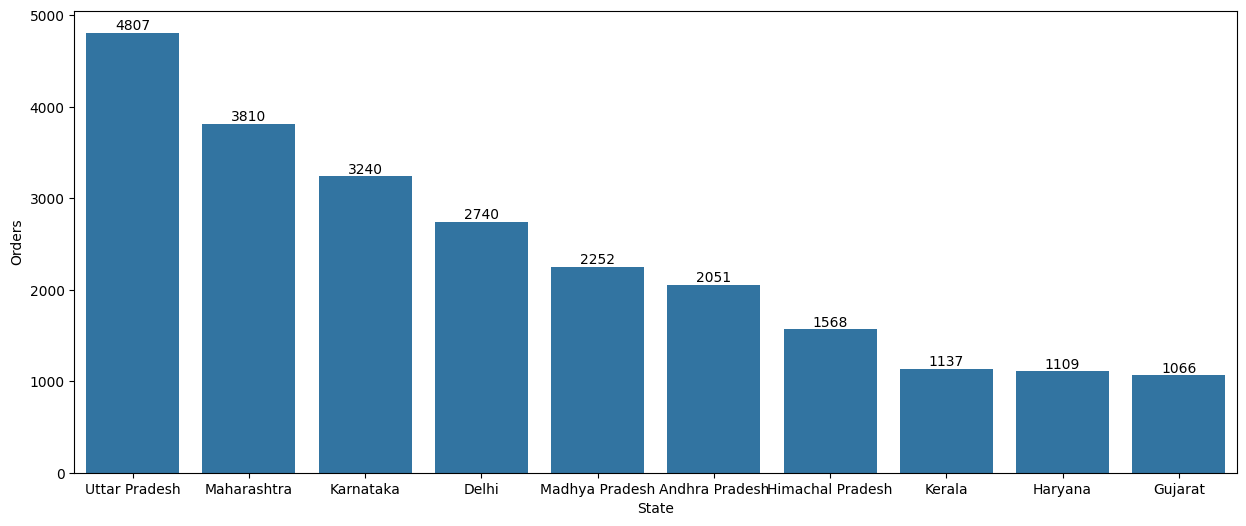

In [84]:
# total number of orders from top 10 states

sales_state = df.groupby(['State'], as_index=False)['Orders'].sum().sort_values(by='Orders', ascending=False).head(10)

plt.figure(figsize=(15, 6))

ax=sns.barplot(data = sales_state, x = 'State',y= 'Orders')

for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='State', ylabel='Amount'>

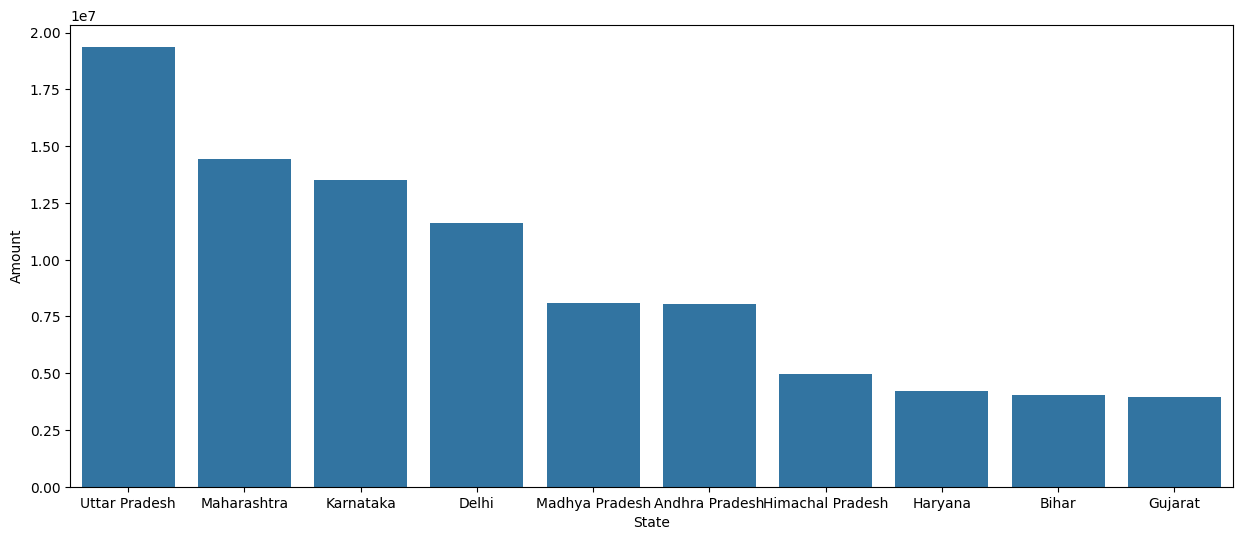

In [85]:
# total amount/sales from top 10 states

sales_state = df.groupby(['State'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False).head(10)

plt.figure(figsize=(15, 6))

sns.barplot(data = sales_state, x = 'State',y= 'Amount')

### Marital Status

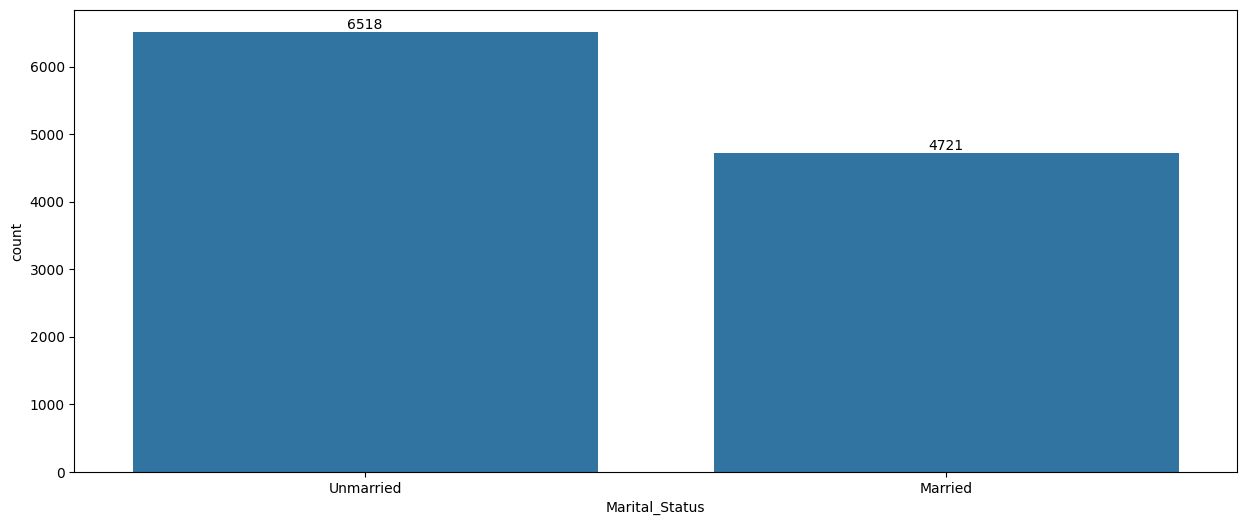

In [ ]:
# Marital status vs Count
df['Marital_Status'] = df['Marital_Status'].map({0:'Unmarried', 1:'Married'})

plt.figure(figsize=(15, 6))

ax = sns.countplot(data = df, x = 'Marital_Status')
for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Marital_Status', ylabel='Amount'>

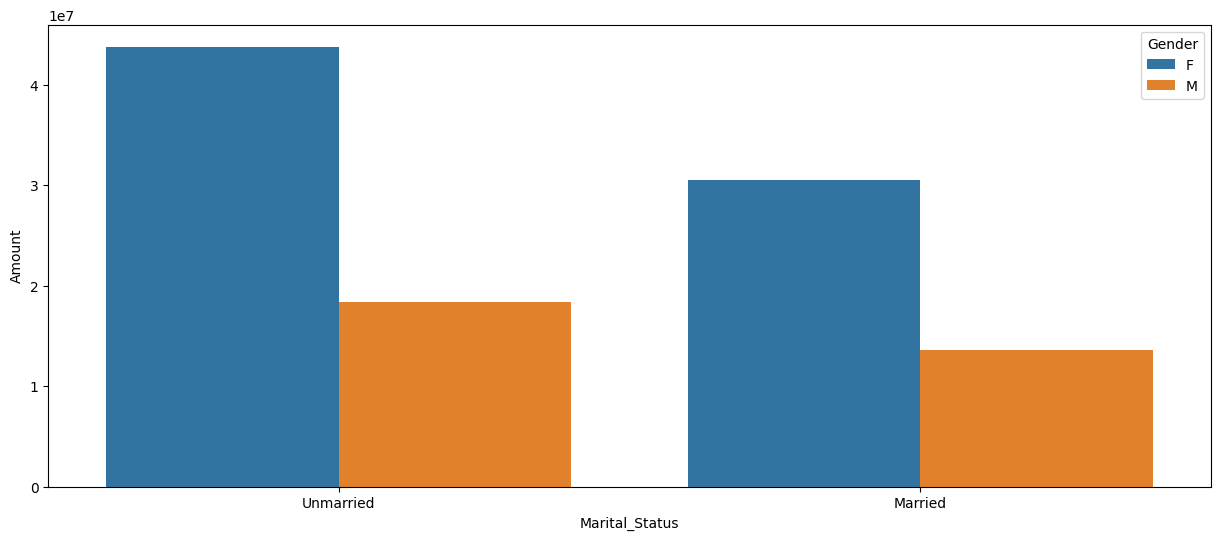

In [87]:
# Marital status vs total amount/sales
sales_state = df.groupby(['Marital_Status', 'Gender'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)
plt.figure(figsize=(15, 6))
sns.barplot(data = sales_state, x = 'Marital_Status',y= 'Amount', hue='Gender')

### Occupation

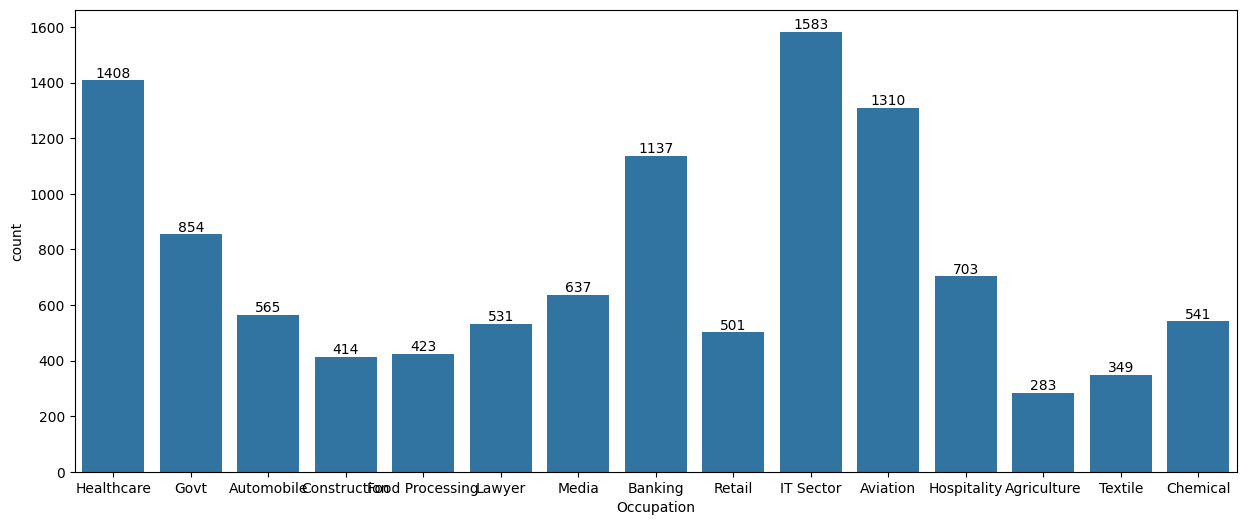

In [88]:
plt.figure(figsize=(15, 6))

ax = sns.countplot(data = df, x = 'Occupation')

for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Occupation', ylabel='Amount'>

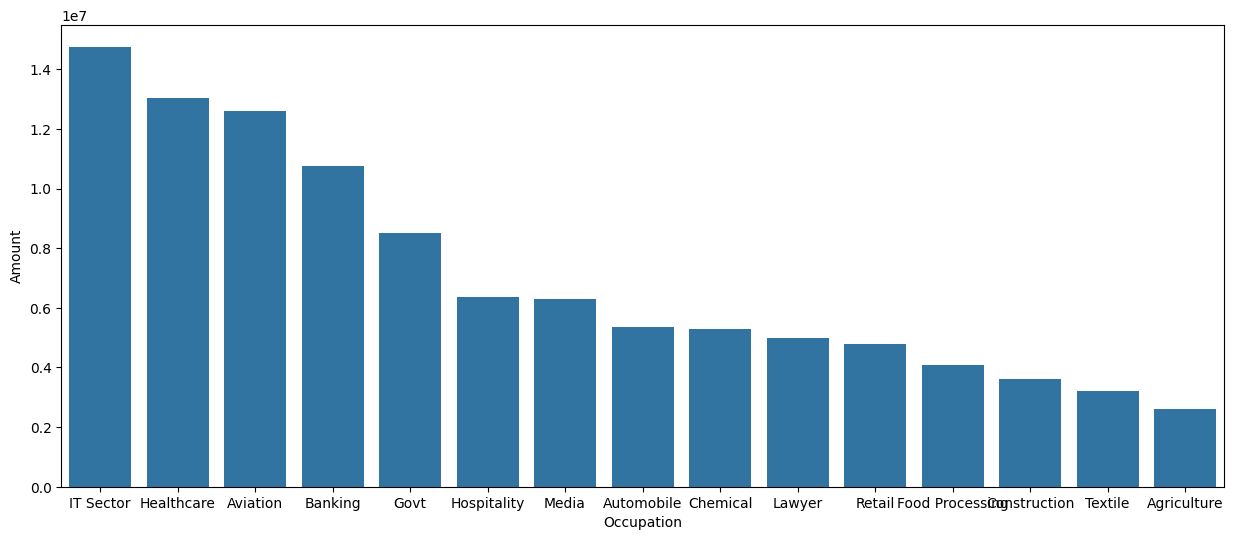

In [89]:
# total amount/sales by occupations
sales_state = df.groupby(['Occupation'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)

plt.figure(figsize=(15, 6))

sns.barplot(data = sales_state, x = 'Occupation',y= 'Amount')

### Product Category

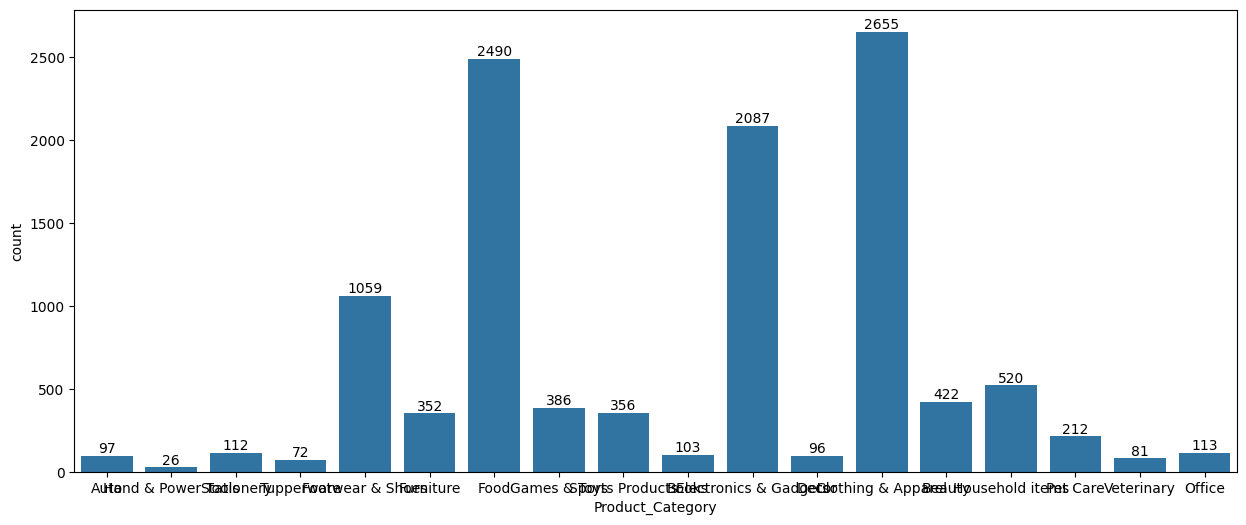

In [90]:
# total number of orders by product category
plt.figure(figsize=(15, 6))

ax = sns.countplot(data = df, x = 'Product_Category')

for bars in ax.containers:
    ax.bar_label(bars)

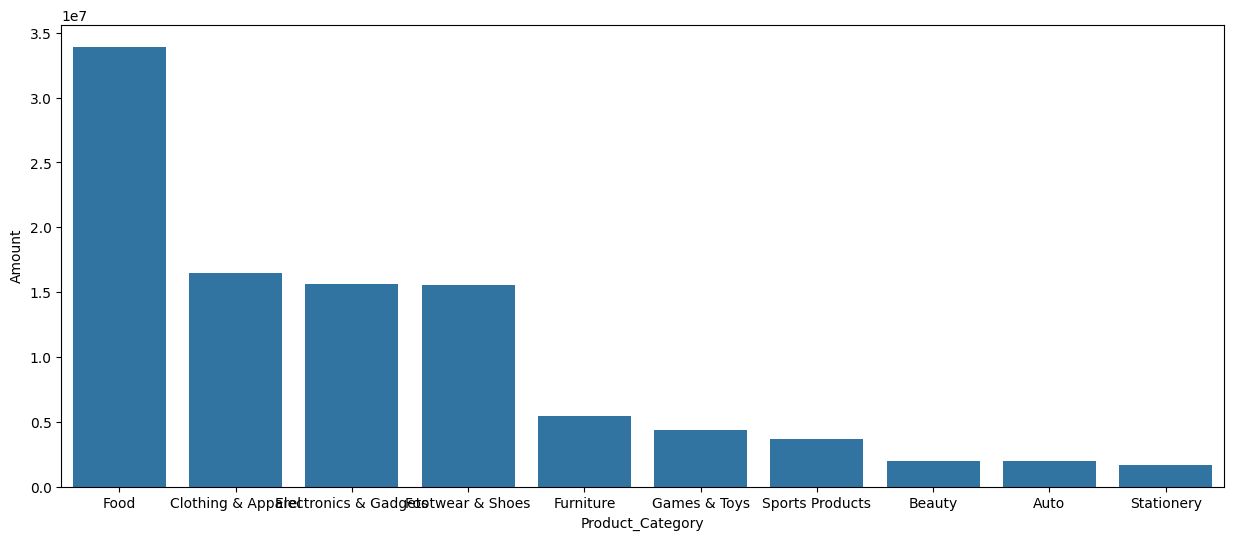

In [91]:
sales_state = df.groupby(['Product_Category'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False).head(10)

plt.figure(figsize=(15, 6))

ax=sns.barplot(data = sales_state, x = 'Product_Category',y= 'Amount')

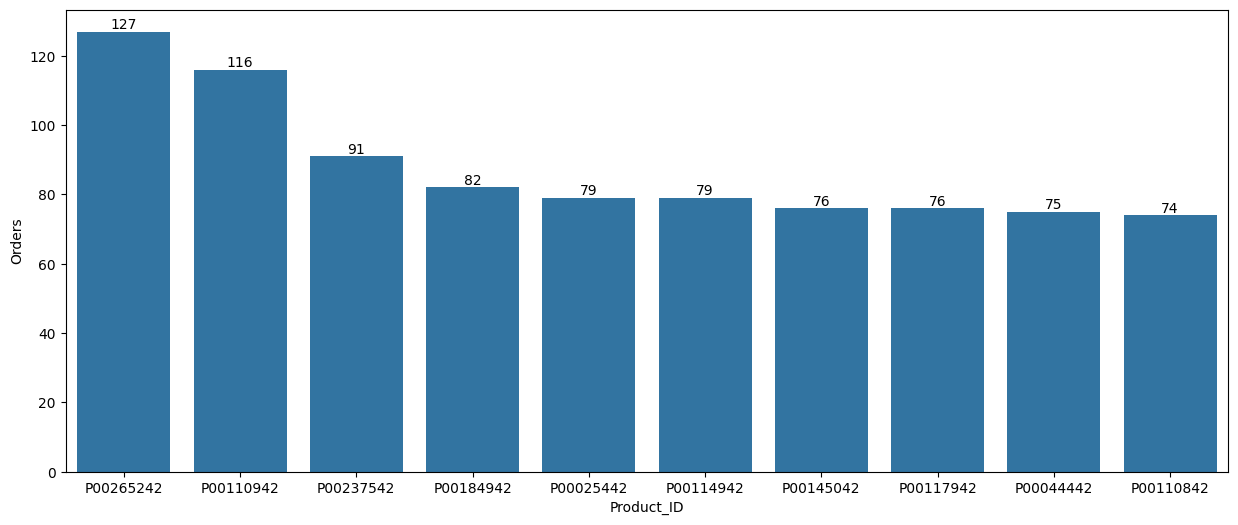

In [92]:
# total number of orders by product ID
sales_state = df.groupby(['Product_ID'], as_index=False)['Orders'].sum().sort_values(by='Orders', ascending=False).head(10)

plt.figure(figsize=(15, 6))

ax=sns.barplot(data = sales_state, x = 'Product_ID',y= 'Orders')

for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Product_ID'>

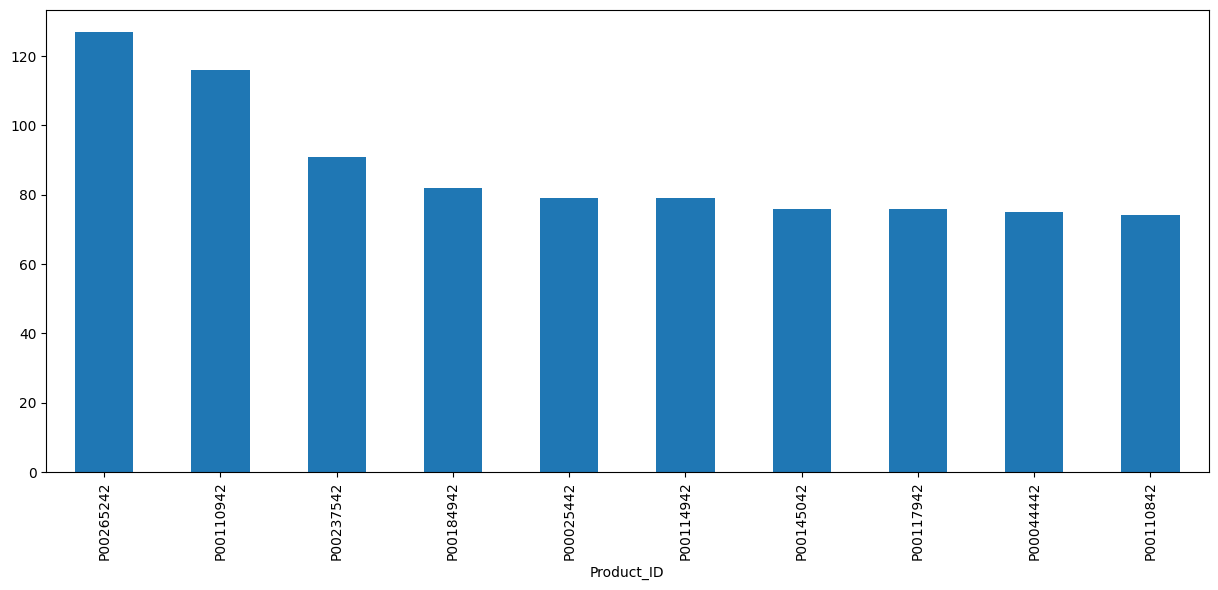

In [93]:
# top 10 most sold products (same thing as above)
plt.figure(figsize=(15, 6))

df.groupby('Product_ID')['Orders'].sum().sort_values(ascending=False).head(10).plot(kind='bar')

# Prediction using Linear Regression

### Prediction Model for Amount based on Age

Predicted Amount of age 26 is 9334.38


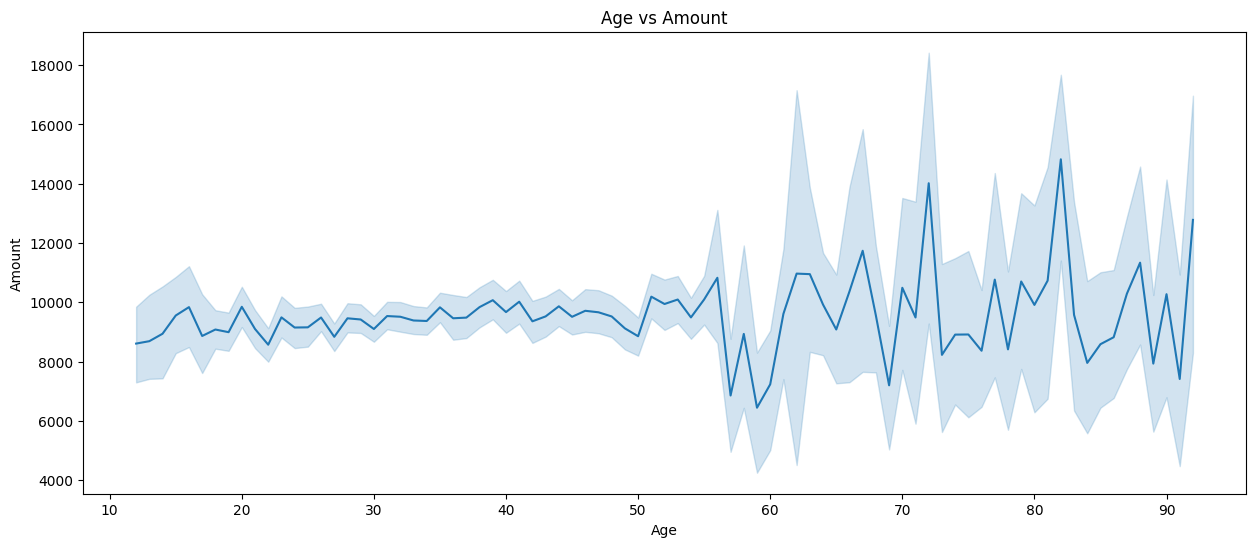

In [94]:
# Prediction Model for Amount based on Age

model1 = LinearRegression()

x=df[['Age']]
y=df['Amount']
model1.fit(x,y)

age=int(input("Enter the age: "))

# DataFrame is necessary to predict otherwise it will give warning
df_age = pd.DataFrame({'Age': [age]})
prediction = model1.predict(df_age)

print(f"Predicted Amount of age {age} is {prediction[0]:.2f}")


plt.figure(figsize=(15, 6))
sns.lineplot(x='Age', y='Amount', data=df)
plt.xlabel('Age')
plt.ylabel('Amount')
plt.title('Age vs Amount')
plt.show()


### Prediction Model on bases of Marital Status

Predicted Amount of marital status Unmarried is 9531.36


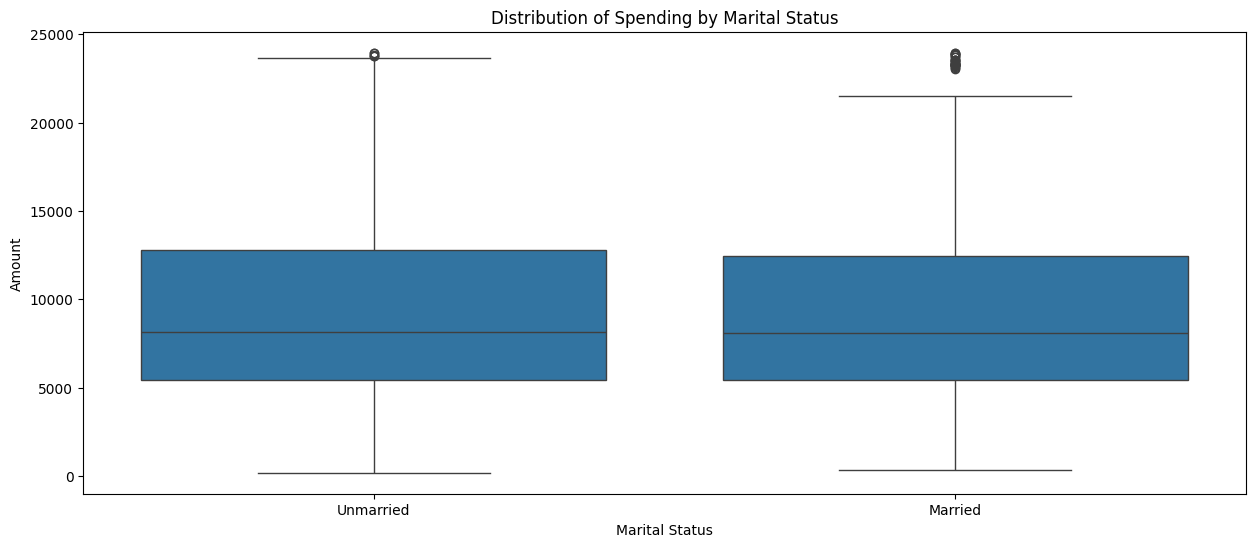

In [95]:
# Prediction Model on bases of Marital Status

df['Marital_Status'] = df['Marital_Status'].map({'Unmarried':0, 'Married':1})
x1=df[['Marital_Status']]
y1=df['Amount']
model1.fit(x1, y1)

marital_status = int(input("Enter Marital Status (1 for Married or 0 for Unmarried): "))

df_marital_status = pd.DataFrame({'Marital_Status': [marital_status]})

prediction = model1.predict(df_marital_status)

# print(prediction)
if marital_status == 1:
    print(f"Predicted Amount of marital status Married is {prediction[0]:.2f}")
else:
    print(f"Predicted Amount of marital status Unmarried is {prediction[0]:.2f}")

df['Marital_Status'] = df['Marital_Status'].map({0: 'Unmarried', 1: 'Married'})

plt.figure(figsize=(15, 6))
sns.boxplot(x='Marital_Status', y='Amount', data=df)
plt.xlabel('Marital Status')
plt.ylabel('Amount')
plt.title('Distribution of Spending by Marital Status')

plt.show()


### Prediction Model on bases of Marital Status and Gender

In [96]:
# Prediction Model on bases of Marital Status and Gender

df['Gender'] = df['Gender'].map({'M':0, 'F':1})
df['Marital_Status'] = df['Marital_Status'].map({'Unmarried':0, 'Married':1})

x1=df[['Gender','Marital_Status']]
y1=df['Amount']
model1.fit(x1,y1)

df_gender=pd.DataFrame({'Gender':[0,0,1,1], 'Marital_Status':[0,1,0,1]})

prediction = model1.predict(df_gender)

df['Gender'] = df['Gender'].map({0: 'Male', 1: 'Female'})

df_gender['Gender']=df_gender['Gender'].map({0:'Male', 1:'Female'})
df_gender['Marital_Status']=df_gender['Marital_Status'].map({0: 'Unmarried', 1: 'Married'})
df_gender['Amount']=df['Amount']

print(f"Predicted Amount for Male whose marital status unmarried is {prediction[0]:.2f} and for married is {prediction[1]:.2f}")
print(f"Predicted Amount for Female whose marital status unmarried is {prediction[2]:.2f} and married is {prediction[3]:.2f}")



Predicted Amount for Male whose marital status unmarried is 9445.81 and for married is 9262.10
Predicted Amount for Female whose marital status unmarried is 9567.74 and married is 9384.03
